**LIVER**

In [ ]:
# install ultralytics
!pip install ultralytics

# import library
import os
import cv2
import yaml
from PIL import Image
import matplotlib.pyplot as plt
from ultralytics import YOLO

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.1/42.1 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.5 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Training Kedua**

In [ ]:
import os

def count_images(path):
    return len(os.listdir(path))

print("Dataset 1 Train:", count_images("/content/drive/MyDrive/DatasetLiver/train/images"))
print("Dataset 2 Train:", count_images("/content/drive/MyDrive/DatasetLiverBaru/train/images"))

Dataset 1 Train: 2782
Dataset 2 Train: 4230


In [ ]:
import os
import shutil

DATASET_1 = "/content/drive/MyDrive/DatasetLiver"
DATASET_2 = "/content/drive/MyDrive/DatasetLiverBaru"
MERGED = "/content/drive/My/Drive/DatasetMerged"

# buat folder
for split in ["train", "valid", "test"]:
    for typ in ["images", "labels"]:
        os.makedirs(f"{MERGED}/{split}/{typ}", exist_ok=True)

def merge_dataset(src, prefix):
    for split in ["train", "valid", "test"]:
        for typ in ["images", "labels"]:
            src_path = f"{src}/{split}/{typ}"
            dst_path = f"{MERGED}/{split}/{typ}"

            if os.path.exists(src_path):
                for file in os.listdir(src_path):
                    new_name = prefix + "_" + file
                    shutil.copy(
                        os.path.join(src_path, file),
                        os.path.join(dst_path, new_name)
                    )

# merge dua dataset
merge_dataset(DATASET_1, "A")
merge_dataset(DATASET_2, "B")

In [ ]:
import os
import shutil

DATASET_1 = "/content/drive/MyDrive/DatasetLiver"
DATASET_2 = "/content/drive/MyDrive/DatasetLiverBaru"
MERGED = "/content/drive/MyDrive/DatasetMergedNew2"

splits = ["train", "valid", "test"]
types = ["images", "labels"]

# 🔹 Buat folder tujuan
for split in splits:
    for typ in types:
        os.makedirs(os.path.join(MERGED, split, typ), exist_ok=True)

# 🔹 Fungsi merge yang aman
def merge_dataset(src, prefix):
    for split in splits:
        img_src = os.path.join(src, split, "images")
        lbl_src = os.path.join(src, split, "labels")

        img_dst = os.path.join(MERGED, split, "images")
        lbl_dst = os.path.join(MERGED, split, "labels")

        if not os.path.exists(img_src) or not os.path.exists(lbl_src):
            print(f"⚠️ Skip {split} di {src} (folder tidak lengkap)")
            continue

        for img_file in os.listdir(img_src):
            # hanya ambil file gambar
            if not img_file.lower().endswith((".jpg", ".jpeg", ".png")):
                continue

            base_name = os.path.splitext(img_file)[0]
            label_file = base_name + ".txt"

            img_path = os.path.join(img_src, img_file)
            lbl_path = os.path.join(lbl_src, label_file)

            # cek apakah label ada
            if not os.path.exists(lbl_path):
                print(f"⚠️ Label tidak ditemukan untuk: {img_file}")
                continue

            # rename biar tidak overwrite
            new_img_name = f"{prefix}_{img_file}"
            new_lbl_name = f"{prefix}_{label_file}"

            shutil.copy(img_path, os.path.join(img_dst, new_img_name))
            shutil.copy(lbl_path, os.path.join(lbl_dst, new_lbl_name))

# 🔥 Jalankan merge
merge_dataset(DATASET_1, "A")
merge_dataset(DATASET_2, "B")

print("✅ Merge selesai!")

✅ Merge selesai!


In [ ]:
import os

BASE_PATH = "/content/drive/MyDrive/DatasetMergedNew2"  # sesuaikan

def count_split(split):
    img_path = os.path.join(BASE_PATH, split, "images")
    lbl_path = os.path.join(BASE_PATH, split, "labels")

    num_images = len(os.listdir(img_path)) if os.path.exists(img_path) else 0
    num_labels = len(os.listdir(lbl_path)) if os.path.exists(lbl_path) else 0

    return num_images, num_labels

for split in ["train", "valid", "test"]:
    imgs, lbls = count_split(split)
    print(f"{split.upper()}: {imgs} images | {lbls} labels")

TRAIN: 7012 images | 7012 labels
VALID: 938 images | 938 labels
TEST: 459 images | 459 labels


In [ ]:
train_imgs, _ = count_split("train")
valid_imgs, _ = count_split("valid")
test_imgs, _ = count_split("test")

total = train_imgs + valid_imgs + test_imgs

print("\n=== DISTRIBUSI DATASET ===")
print(f"Train: {train_imgs} ({train_imgs/total:.2%})")
print(f"Valid: {valid_imgs} ({valid_imgs/total:.2%})")
print(f"Test : {test_imgs} ({test_imgs/total:.2%})")


=== DISTRIBUSI DATASET ===
Train: 7012 (83.39%)
Valid: 938 (11.15%)
Test : 459 (5.46%)


In [ ]:
from collections import Counter

def count_classes(label_path):
    class_count = Counter()

    for file in os.listdir(label_path):
        with open(os.path.join(label_path, file)) as f:
            for line in f.readlines():
                cls = int(line.split()[0])
                class_count[cls] += 1

    return class_count

train_label_path = os.path.join(BASE_PATH, "train", "labels")
class_dist = count_classes(train_label_path)

print("\n=== DISTRIBUSI CLASS (TRAIN) ===")
for k, v in class_dist.items():
    print(f"Class {k}: {v}")


=== DISTRIBUSI CLASS (TRAIN) ===
Class 2: 16800
Class 1: 3930
Class 3: 14810
Class 0: 4710


In [ ]:
import os
import random
import shutil
from collections import defaultdict, Counter

# =========================
# PATH (SESUAIKAN)
# =========================
BASE_PATH = "/content/drive/MyDrive/DatasetMergedNew2"
BALANCED_PATH = "/content/drive/MyDrive/DatasetBalancedNewLiver2"

TARGET = 6000  # target max per class

IMG_EXT = [".jpg", ".jpeg", ".png"]

# =========================
# BUAT FOLDER
# =========================
for split in ["train"]:
    for typ in ["images", "labels"]:
        os.makedirs(os.path.join(BALANCED_PATH, split, typ), exist_ok=True)

# =========================
# MAPPING FILE → CLASS
# =========================
label_dir = os.path.join(BASE_PATH, "train", "labels")

class_files = defaultdict(list)

for file in os.listdir(label_dir):
    if not file.endswith(".txt"):
        continue

    with open(os.path.join(label_dir, file)) as f:
        classes = [int(line.split()[0]) for line in f.readlines()]

        for cls in set(classes):  # hindari duplikat
            class_files[cls].append(file)

# =========================
# PILIH FILE SESUAI TARGET
# =========================
selected_files = set()

for cls, files in class_files.items():
    print(f"Class {cls} sebelum: {len(files)}")

    if len(files) > TARGET:
        sampled = random.sample(files, TARGET)
    else:
        sampled = files

    selected_files.update(sampled)

# =========================
# COPY FILE (IMAGE + LABEL)
# =========================
img_src = os.path.join(BASE_PATH, "train", "images")
lbl_src = os.path.join(BASE_PATH, "train", "labels")

img_dst = os.path.join(BALANCED_PATH, "train", "images")
lbl_dst = os.path.join(BALANCED_PATH, "train", "labels")

copied = 0

for lbl_file in selected_files:
    base = os.path.splitext(lbl_file)[0]

    # cari file gambar (support multi format)
    img_file = None
    for ext in IMG_EXT:
        if os.path.exists(os.path.join(img_src, base + ext)):
            img_file = base + ext
            break

    if img_file is None:
        print(f"⚠️ Gambar tidak ditemukan untuk {base}")
        continue

    shutil.copy(
        os.path.join(img_src, img_file),
        os.path.join(img_dst, img_file)
    )

    shutil.copy(
        os.path.join(lbl_src, lbl_file),
        os.path.join(lbl_dst, lbl_file)
    )

    copied += 1

print(f"\n✅ Total file ter-copy: {copied}")

Class 2 sebelum: 1495
Class 1 sebelum: 1820
Class 3 sebelum: 1827
Class 0 sebelum: 1863

✅ Total file ter-copy: 7004


In [ ]:
from collections import Counter

label_dir = "/content/drive/MyDrive/DatasetBalancedNewLiver2/train/labels"

counter = Counter()

for file in os.listdir(label_dir):
    with open(os.path.join(label_dir, file)) as f:
        for line in f.readlines():
            cls = int(line.split()[0])
            counter[cls] += 1

print("\n=== DISTRIBUSI SETELAH BALANCING ===")
for k, v in counter.items():
    print(f"Class {k}: {v}")


=== DISTRIBUSI SETELAH BALANCING ===
Class 2: 16800
Class 0: 4710
Class 3: 14810
Class 1: 3930


In [ ]:
import os
import cv2
import random
import shutil

BASE_PATH = "/content/drive/MyDrive/DatasetMergedNew2"
AUG_PATH = "/content/drive/MyDrive/DatasetAugmentedMergedLiver2"

TARGET_CLASSES = [0, 1]  # class kecil
AUG_TIMES = 2  # berapa kali augment per gambar

# buat folder
for split in ["train"]:
    for typ in ["images", "labels"]:
        os.makedirs(f"{AUG_PATH}/{split}/{typ}", exist_ok=True)

img_src = f"{BASE_PATH}/train/images"
lbl_src = f"{BASE_PATH}/train/labels"

img_dst = f"{AUG_PATH}/train/images"
lbl_dst = f"{AUG_PATH}/train/labels"

# copy semua data asli dulu
for file in os.listdir(img_src):
    shutil.copy(os.path.join(img_src, file), os.path.join(img_dst, file))

for file in os.listdir(lbl_src):
    shutil.copy(os.path.join(lbl_src, file), os.path.join(lbl_dst, file))

# fungsi augmentasi
def augment_image(img):
    # flip horizontal
    if random.random() < 0.5:
        img = cv2.flip(img, 1)

    # flip vertical
    if random.random() < 0.3:
        img = cv2.flip(img, 0)

    # brightness
    if random.random() < 0.5:
        value = random.randint(-30, 30)
        img = cv2.convertScaleAbs(img, alpha=1, beta=value)

    return img

# augment khusus class kecil
count_aug = 0

for lbl_file in os.listdir(lbl_src):

    with open(os.path.join(lbl_src, lbl_file)) as f:
        classes = [int(line.split()[0]) for line in f.readlines()]

    # cek apakah ada class kecil
    if not any(c in TARGET_CLASSES for c in classes):
        continue

    base = os.path.splitext(lbl_file)[0]

    # cari gambar
    img_file = None
    for ext in [".jpg", ".png", ".jpeg"]:
        if os.path.exists(os.path.join(img_src, base + ext)):
            img_file = base + ext
            break

    if img_file is None:
        continue

    img = cv2.imread(os.path.join(img_src, img_file))

    for i in range(AUG_TIMES):
        aug_img = augment_image(img)

        new_name = f"{base}_aug_{i}"

        # simpan gambar
        cv2.imwrite(os.path.join(img_dst, new_name + ".jpg"), aug_img)

        # copy label (tetap sama)
        shutil.copy(
            os.path.join(lbl_src, lbl_file),
            os.path.join(lbl_dst, new_name + ".txt")
        )

        count_aug += 1

print(f"✅ Total augmentasi dibuat: {count_aug}")

✅ Total augmentasi dibuat: 7366


In [ ]:
from collections import Counter

counter = Counter()

for file in os.listdir(f"{AUG_PATH}/train/labels"):
    with open(os.path.join(f"{AUG_PATH}/train/labels", file)) as f:
        for line in f.readlines():
            cls = int(line.split()[0])
            counter[cls] += 1

print(counter)

Counter({2: 16800, 3: 14810, 0: 14130, 1: 11790})


In [ ]:
import os
import shutil

BASE_PATH = "/content/drive/MyDrive/DatasetMergedNew2"
AUG_PATH  = "/content/drive/MyDrive/DatasetAugmentedMergedLiver2"

for split in ["valid", "test"]:
    src = os.path.join(BASE_PATH, split)
    dst = os.path.join(AUG_PATH, split)

    # cek apakah source ada
    if not os.path.exists(src):
        print(f"❌ Folder tidak ditemukan: {src}")
        continue

    # buat folder tujuan dulu
    os.makedirs(dst, exist_ok=True)

    # copy isi folder (bukan foldernya)
    for item in os.listdir(src):
        s = os.path.join(src, item)
        d = os.path.join(dst, item)

        if os.path.isdir(s):
            shutil.copytree(s, d, dirs_exist_ok=True)
        else:
            shutil.copy2(s, d)

    print(f"✅ {split} berhasil dipindahkan")

print("🔥 Selesai semua!")

✅ valid berhasil dipindahkan
✅ test berhasil dipindahkan
🔥 Selesai semua!


In [ ]:
print("\nIsi test/images:")
print(os.listdir("/content/drive/MyDrive/DatasetMergedNew2/test/images"))

print("\nIsi test/labels:")
print(os.listdir("/content/drive/MyDrive/DatasetMergedNew2/test/labels"))


Isi test/images:
['A_18_228_Masson_207_34_34_jpg.rf.0471cf32e06ba7259c9e3a6d3fcad847.jpg', 'A_18_217_212_56_22_jpg.rf.261af1b4d1fe5a273589a4f4f8cb276e.jpg', 'A_15_242_212_22_18_jpg.rf.2507ed18caf750785ad603530130319e.jpg', 'A_18_229_Masson_201_36_15_jpg.rf.1911b3cf7f72c41a990f2d2cbdfb9baa.jpg', 'A_15_242_212_25_20_jpg.rf.0e1711a2ca5c5d3edb0f4d1d983dfd61.jpg', 'A_18_228_Masson_505_93_23_jpg.rf.170b2bbf851c879138ccc80e07dfe8c6.jpg', 'A_18_229_Masson_202_96_27_jpg.rf.2e660f0f87088edd32bcbb76633375c6.jpg', 'A_208_5_18_29_jpg.rf.31f1e544a9cc74b1d28f7f2297a6e1f8.jpg', 'A_18_217_218_53_27_jpg.rf.34a8753fe7d27c467411fb07c5b93476.jpg', 'A_206_4_4_38_jpg.rf.17197d535b9787189828203774cbc60e.jpg', 'A_208_2_9_5_jpg.rf.08a49249cb1cffa43547f9bc146890cc.jpg', 'A_18_236_203_76_7_jpg.rf.046d3671f710abc2077b9ede2e4039a9.jpg', 'A_202_4_9_11_jpg.rf.00c325b35b75832eb966c50ffd3fc41e.jpg', 'A_201_3_8_32_jpg.rf.27936ceedef5d3c75243b307a921f3e8.jpg', 'A_18_228_Masson_505_88_28_jpg.rf.1c8034f2bd937afb4bd402a19f

In [ ]:
yaml_content = """path: /content/drive/MyDrive/DatasetAugmentedMergedLiver2

train: train/images
val: valid/images
test: test/images

nc: 4

names:
  0: ballooning
  1: fibrosis
  2: inflammation
  3: steatosis
"""

with open("/content/drive/MyDrive/DatasetAugmentedMergedLiver2/data.yaml", "w") as f:
    f.write(yaml_content)

print("✅ data.yaml berhasil dibuat")

✅ data.yaml berhasil dibuat


In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11m.pt")

model.train(
    data="/content/drive/MyDrive/DatasetAugmentedMergedLiver2/data.yaml",
    epochs=150,
    imgsz=640,
    batch=16,

    lr0=0.0008,
    lrf=0.01,

    hsv_h=0.015,
    hsv_s=0.5,
    hsv_v=0.3,
    fliplr=0.5,
    flipud=0.3,
    mosaic=0.4,
    mixup=0.1,

    patience=30,

    project="/content/drive/MyDrive/yolo_results_Juni_2026",
    name="liver_yolo11_final_Juni_2026"
)

Ultralytics 8.4.66 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/DatasetAugmentedMergedLiver2/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.3, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.5, hsv_v=0.3, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0008, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=0.4, multi_scale=0.0, name=liver_yolo11_final_Juni_2026, nbs=64, nms=False, opset

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7efd258ca270>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0

In [ ]:
import os
import cv2
import random
import shutil

BASE_PATH = "/content/drive/MyDrive/DatasetMergedNew2/train"
AUG_PATH  = "/content/drive/MyDrive/DatasetAugmentedMergedLiver2/train"

IMG_PATH = os.path.join(BASE_PATH, "images")
LBL_PATH = os.path.join(BASE_PATH, "labels")

AUG_IMG = os.path.join(AUG_PATH, "images")
AUG_LBL = os.path.join(AUG_PATH, "labels")

os.makedirs(AUG_IMG, exist_ok=True)
os.makedirs(AUG_LBL, exist_ok=True)

TARGET_CLASS = 1  # fibrosis

def is_fibrosis(label_file):
    with open(label_file, "r") as f:
        for line in f:
            if int(line.split()[0]) == TARGET_CLASS:
                return True
    return False

def augment_image(img):
    aug_list = []

    # flip horizontal
    aug_list.append(cv2.flip(img, 1))

    # rotate kecil
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w/2, h/2), random.uniform(-10, 10), 1)
    aug_list.append(cv2.warpAffine(img, M, (w, h)))

    # brightness
    bright = cv2.convertScaleAbs(img, alpha=1, beta=random.randint(-30, 30))
    aug_list.append(bright)

    # blur ringan
    aug_list.append(cv2.GaussianBlur(img, (5,5), 0))

    return aug_list

count = 0

for file in os.listdir(IMG_PATH):
    img_file = os.path.join(IMG_PATH, file)
    lbl_file = os.path.join(LBL_PATH, file.replace(".jpg", ".txt"))

    if not os.path.exists(lbl_file):
        continue

    # cek apakah fibrosis
    if is_fibrosis(lbl_file):
        img = cv2.imread(img_file)

        aug_images = augment_image(img)

        for i, aug in enumerate(aug_images):
            new_name = f"fib_aug_{count}_{i}.jpg"
            cv2.imwrite(os.path.join(AUG_IMG, new_name), aug)

            # copy label (tetap sama)
            shutil.copy(lbl_file,
                        os.path.join(AUG_LBL, new_name.replace(".jpg", ".txt")))

        count += 1

print(f"✅ Augmentasi fibrosis selesai: {count} gambar diproses")

✅ Augmentasi fibrosis selesai: 1820 gambar diproses


In [ ]:
from ultralytics import YOLO

# ======================
# LOAD MODEL TERBAIK SEBELUMNYA
# ======================
model = YOLO("/content/drive/MyDrive/yolo_results_Juni_2026/liver_yolo11_final_Juni_2026/weights/best.pt")

# ======================
# TRAIN / FINETUNE
# ======================
model.train(
    data="/content/drive/MyDrive/DatasetAugmentedMergedLiver2/data.yaml",

    # ======================
    # TRAINING
    # ======================
    epochs=100,
    imgsz=640,
    batch=16,

    # ======================
    # LEARNING RATE (LEBIH KECIL → FINETUNE)
    # ======================
    lr0=0.0003,
    lrf=0.01,

    # ======================
    # AUGMENTASI (RINGAN)
    # ======================
    hsv_h=0.015,
    hsv_s=0.5,
    hsv_v=0.3,
    fliplr=0.5,
    flipud=0.3,
    mosaic=0.3,
    mixup=0.1,

    # ======================
    # EARLY STOPPING
    # ======================
    patience=40,

    # ======================
    # PERFORMANCE
    # ======================
    device=0,
    workers=2,

    # ======================
    # SIMPAN KE GOOGLE DRIVE 🔥
    # ======================
    project="/content/drive/MyDrive/yolo_results_Juni_2026",
    name="liver_yolo11_finetune_fibrosis",

    # ======================
    # TAMBAHAN
    # ======================
    pretrained=True,
    verbose=True
)

Ultralytics 8.4.66 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/DatasetAugmentedMergedLiver2/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.3, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.5, hsv_v=0.3, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0003, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=/content/drive/MyDrive/yolo_results_Juni_2026/liver_yolo11_final_Juni_2026/weights/best.pt, momentum=0.937, mosaic=0.3,

In [ ]:
from ultralytics import YOLO

model = YOLO("/content/drive/MyDrive/yolo_results_Juni_2026/liver_yolo11_final_Juni_2026/weights/best.pt")

In [ ]:
from ultralytics import YOLO
import cv2
from IPython.display import display, Image
import os # Import os for path manipulation

# load model
model = YOLO("/content/drive/MyDrive/yolo_results_Juni_2026/liver_yolo11_final_Juni_2026/weights/best.pt")

# predict
results = model.predict(
    source="/content/drive/MyDrive/DatasetAugmentedMergedLiver2/test/images/A_15_242_208_22_23_jpg.rf.299ae4e3df3556c386d27adea3aeddab.jpg",
    conf=0.25,
    save=True
)

# ambil hasil pertama
result = results[0]

# Construct the expected path for the saved image
# Ultralytics typically saves the processed image with the original filename in the results.save_dir
predicted_image_filename = os.path.basename(result.path)
output_image_path = os.path.join(result.save_dir, predicted_image_filename)

# Check if any objects were detected
if len(result.boxes) > 0:
    # Verify if the output image actually exists before trying to display it
    if os.path.exists(output_image_path):
        # tampilkan gambar hasil
        display(Image(filename=output_image_path))
    else:
        print(f"Warning: Objects were detected, but the output image '{predicted_image_filename}' was not found at '{result.save_dir}'.")
        print("Please check the Ultralytics saving behavior or the path construction.")

    # ======================
    # PRINT HASIL CLASS
    # ======================
    names = model.names

    print("\n=== HASIL DETEKSI ===")
    for box in result.boxes:
        cls_id = int(box.cls[0])
        conf = float(box.conf[0])

        print(f"Class: {names[cls_id]} | Confidence: {conf:.2f}")
else:
    print("No objects detected in the image.")
    print("No image with detections will be displayed.")


image 1/1 /content/drive/MyDrive/DatasetAugmentedMergedLiver2/test/images/A_15_242_208_22_23_jpg.rf.299ae4e3df3556c386d27adea3aeddab.jpg: 640x640 (no detections), 12.8ms
Speed: 2.5ms preprocess, 12.8ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict-16
No objects detected in the image.
No image with detections will be displayed.


HYBRID JOIN

In [ ]:
BASE_PATH = "/content/drive/MyDrive/hybrid_model_liver"

import os
os.makedirs(BASE_PATH, exist_ok=True)
os.makedirs(BASE_PATH + "/xgboost", exist_ok=True)
os.makedirs(BASE_PATH + "/features", exist_ok=True)

In [ ]:
from ultralytics import YOLO
import torch
import torchvision.models as models

# YOLO (pakai sebelum finetune)
yolo_model = YOLO("/content/drive/MyDrive/yolo_results_Juni_2026/liver_yolo11_final_Juni_2026/weights/best.pt")

# RESNET
device = 'cuda' if torch.cuda.is_available() else 'cpu'

resnet = models.resnet50(pretrained=True)
resnet = torch.nn.Sequential(*list(resnet.children())[:-1])
resnet = resnet.to(device)
resnet.eval()

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 242MB/s]


Sequential(
  (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (4): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)


**ResNet OLD**

In [ ]:
import os
import cv2
import numpy as np
import torch
from tqdm import tqdm
from PIL import Image
import torchvision.transforms as transforms

# ======================
# DEVICE
# ======================
device = "cuda" if torch.cuda.is_available() else "cpu"

# ======================
# TRANSFORM
# ======================
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

# ======================
# RESNET SETUP (FEATURE EXTRACTOR)
# ======================
import torchvision.models as models
import torch.nn as nn

resnet = models.resnet50(pretrained=True)
resnet = nn.Sequential(*list(resnet.children())[:-1])  # remove FC
resnet = resnet.to(device)
resnet.eval()

for param in resnet.parameters():
    param.requires_grad = False

# ======================
# PATH
# ======================
DATA_PATH = "/content/drive/MyDrive/DatasetAugmentedMergedLiver2/train/images"
BASE_PATH = "/content/drive/MyDrive/hybrid_model_liver"

os.makedirs(BASE_PATH + "/features", exist_ok=True)

files = os.listdir(DATA_PATH)

# ======================
# PARAMETER
# ======================
BATCH_SIZE = 32   # bisa dinaikkan kalau GPU kuat

X, y = [], []

# ======================
# LOOP BATCH YOLO
# ======================
for i in tqdm(range(0, len(files), BATCH_SIZE), desc="Processing"):

    batch_files = files[i:i+BATCH_SIZE]
    batch_imgs = []
    valid_files = []

    # load image
    for file in batch_files:
        path = os.path.join(DATA_PATH, file)
        img = cv2.imread(path)

        if img is None:
            continue

        batch_imgs.append(img)
        valid_files.append(file)

    if len(batch_imgs) == 0:
        continue

    # ======================
    # YOLO BATCH INFERENCE
    # ======================
    results = yolo_model(batch_imgs, conf=0.15)

    crops = []
    labels = []

    # ======================
    # EXTRACT CROPS
    # ======================
    for img, result in zip(batch_imgs, results):

        if len(result.boxes) == 0:
            continue  # skip no detection

        h, w, _ = img.shape

        for box in result.boxes:
            cls = int(box.cls[0])
            x1, y1, x2, y2 = map(int, box.xyxy[0])

            # safe crop
            x1, y1 = max(0, x1), max(0, y1)
            x2, y2 = min(w, x2), min(h, y2)

            crop = img[y1:y2, x1:x2]

            if crop.size == 0:
                continue

            if crop.shape[0] < 20 or crop.shape[1] < 20:
                continue

            crops.append(crop)
            labels.append(cls)

    # ======================
    # RESNET BATCH FEATURE EXTRACTION
    # ======================
    if len(crops) > 0:
        imgs = [transform(Image.fromarray(c)) for c in crops]
        imgs = torch.stack(imgs).to(device)

        with torch.no_grad():
            feats = resnet(imgs)

        feats = feats.cpu().numpy().reshape(len(crops), -1)

        X.extend(feats)
        y.extend(labels)

# ======================
# SAVE
# ======================
X = np.array(X)
y = np.array(y)

np.save(BASE_PATH + "/features/X.npy", X)
np.save(BASE_PATH + "/features/y.npy", y)

print("✅ SELESAI!")
print("Shape X:", X.shape)
print("Shape y:", y.shape)

Processing:   0%|          | 0/677 [00:00<?, ?it/s]


0: 640x640 (no detections), 3.4ms
1: 640x640 (no detections), 3.4ms
2: 640x640 1 fibrosis, 3.4ms
3: 640x640 (no detections), 3.4ms
4: 640x640 3 fibrosiss, 3.4ms
5: 640x640 1 fibrosis, 3.4ms
6: 640x640 3 fibrosiss, 3.4ms
7: 640x640 1 fibrosis, 3.4ms
8: 640x640 1 fibrosis, 3.4ms
9: 640x640 (no detections), 3.4ms
10: 640x640 1 fibrosis, 3.4ms
11: 640x640 (no detections), 3.4ms
12: 640x640 1 fibrosis, 3.4ms
13: 640x640 1 fibrosis, 3.4ms
14: 640x640 2 fibrosiss, 3.4ms
15: 640x640 2 fibrosiss, 3.4ms
16: 640x640 2 fibrosiss, 3.4ms
17: 640x640 2 fibrosiss, 3.4ms
18: 640x640 1 fibrosis, 3.4ms
19: 640x640 (no detections), 3.4ms
20: 640x640 2 fibrosiss, 3.4ms
21: 640x640 2 fibrosiss, 3.4ms
22: 640x640 3 fibrosiss, 3.4ms
23: 640x640 1 fibrosis, 3.4ms
24: 640x640 2 fibrosiss, 3.4ms
25: 640x640 (no detections), 3.4ms
26: 640x640 4 fibrosiss, 3.4ms
27: 640x640 1 fibrosis, 3.4ms
28: 640x640 1 fibrosis, 3.4ms
29: 640x640 1 fibrosis, 3.4ms
30: 640x640 1 fibrosis, 3.4ms
31: 640x640 1 fibrosis, 1 steatos

Processing:   0%|          | 1/677 [00:00<05:16,  2.14it/s]


0: 640x640 1 fibrosis, 2.3ms
1: 640x640 (no detections), 2.3ms
2: 640x640 (no detections), 2.3ms
3: 640x640 (no detections), 2.3ms
4: 640x640 2 fibrosiss, 2.3ms
5: 640x640 1 fibrosis, 2.3ms
6: 640x640 2 fibrosiss, 2.3ms
7: 640x640 2 fibrosiss, 2.3ms
8: 640x640 2 fibrosiss, 2.3ms
9: 640x640 3 fibrosiss, 2.3ms
10: 640x640 2 fibrosiss, 2.3ms
11: 640x640 (no detections), 2.3ms
12: 640x640 (no detections), 2.3ms
13: 640x640 1 fibrosis, 2.3ms
14: 640x640 (no detections), 2.3ms
15: 640x640 (no detections), 2.3ms
16: 640x640 2 fibrosiss, 2.3ms
17: 640x640 1 fibrosis, 2.3ms
18: 640x640 1 fibrosis, 2.3ms
19: 640x640 1 fibrosis, 2.3ms
20: 640x640 2 fibrosiss, 2.3ms
21: 640x640 2 fibrosiss, 2.3ms
22: 640x640 2 fibrosiss, 2.3ms
23: 640x640 2 fibrosiss, 2.3ms
24: 640x640 1 fibrosis, 2.3ms
25: 640x640 1 fibrosis, 2.3ms
26: 640x640 1 fibrosis, 2.3ms
27: 640x640 (no detections), 2.3ms
28: 640x640 1 fibrosis, 2.3ms
29: 640x640 (no detections), 2.3ms
30: 640x640 1 fibrosis, 2.3ms
31: 640x640 1 balloonin

Processing:   0%|          | 2/677 [00:00<04:49,  2.33it/s]


0: 640x640 (no detections), 2.3ms
1: 640x640 (no detections), 2.3ms
2: 640x640 (no detections), 2.3ms
3: 640x640 (no detections), 2.3ms
4: 640x640 3 fibrosiss, 2.3ms
5: 640x640 2 fibrosiss, 2.3ms
6: 640x640 3 fibrosiss, 2.3ms
7: 640x640 2 fibrosiss, 2.3ms
8: 640x640 1 fibrosis, 2.3ms
9: 640x640 1 fibrosis, 2.3ms
10: 640x640 1 fibrosis, 2.3ms
11: 640x640 1 fibrosis, 2.3ms
12: 640x640 1 fibrosis, 2.3ms
13: 640x640 1 fibrosis, 2.3ms
14: 640x640 1 fibrosis, 2.3ms
15: 640x640 1 fibrosis, 2.3ms
16: 640x640 (no detections), 2.3ms
17: 640x640 (no detections), 2.3ms
18: 640x640 (no detections), 2.3ms
19: 640x640 2 fibrosiss, 2.3ms
20: 640x640 2 fibrosiss, 2.3ms
21: 640x640 2 fibrosiss, 2.3ms
22: 640x640 2 fibrosiss, 2.3ms
23: 640x640 1 fibrosis, 2.3ms
24: 640x640 3 fibrosiss, 2.3ms
25: 640x640 1 fibrosis, 2.3ms
26: 640x640 2 fibrosiss, 2.3ms
27: 640x640 2 fibrosiss, 2.3ms
28: 640x640 2 fibrosiss, 2.3ms
29: 640x640 (no detections), 2.3ms
30: 640x640 3 fibrosiss, 2.3ms
31: 640x640 1 fibrosis, 2.

... (1,346 outputs left out)

Processing: 100%|█████████▉| 676/677 [16:53<00:00,  1.02it/s]


0: 640x640 7 steatosiss, 2.9ms
1: 640x640 18 inflammations, 2.9ms
2: 640x640 9 steatosiss, 2.9ms
3: 640x640 5 balloonings, 2.9ms
4: 640x640 5 balloonings, 2.9ms
5: 640x640 6 fibrosiss, 2.9ms
6: 640x640 53 inflammations, 2.9ms
7: 640x640 4 fibrosiss, 2.9ms
8: 640x640 1 ballooning, 2.9ms
9: 640x640 8 fibrosiss, 2.9ms
10: 640x640 10 steatosiss, 2.9ms
11: 640x640 6 inflammations, 2.9ms
12: 640x640 29 inflammations, 2.9ms
13: 640x640 5 fibrosiss, 2.9ms
14: 640x640 1 fibrosis, 2.9ms
15: 640x640 3 fibrosiss, 2.9ms
16: 640x640 30 inflammations, 2.9ms
17: 640x640 5 fibrosiss, 2.9ms
18: 640x640 6 fibrosiss, 2.9ms
19: 640x640 10 steatosiss, 2.9ms
20: 640x640 14 steatosiss, 2.9ms
21: 640x640 2 fibrosiss, 2.9ms
22: 640x640 24 inflammations, 2.9ms
23: 640x640 1 ballooning, 2.9ms
24: 640x640 2 balloonings, 2.9ms
25: 640x640 3 balloonings, 2.9ms
Speed: 1.8ms preprocess, 2.9ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 640)


Processing: 100%|██████████| 677/677 [16:54<00:00,  1.50s/it]


✅ SELESAI!
Shape X: (85195, 2048)
Shape y: (85195,)


RESNET BARU

In [ ]:
import os
import cv2
import numpy as np
import torch
from tqdm import tqdm
from PIL import Image
import torchvision.transforms as transforms
import torchvision.models as models
import torch.nn as nn
from ultralytics import YOLO

# ========================================================
# 1. SETUP DEVICE & TRANSFORMASI IMAGES FOR RESNET
# ========================================================
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Menggunakan device: {device}")

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

# ========================================================
# 2. LOAD MODEL YOLOv11 HASIL TRAINING & RESNET50
# ========================================================
# Load model YOLO yang baru saja kamu train di atas
YOLO_WEIGHTS_PATH = "/content/drive/MyDrive/yolo_results_Juni_2026/liver_yolo11_final_Juni_2026/weights/best.pt"
yolo_model = YOLO(YOLO_WEIGHTS_PATH)

# Load ResNet50 bawaan PyTorch sebagai feature extractor (Freeze bobot)
resnet = models.resnet50(pretrained=True)
resnet = nn.Sequential(*list(resnet.children())[:-1])  # Buang layer klasifikasi FC terakhir
resnet = resnet.to(device)
resnet.eval()

for param in resnet.parameters():
    param.requires_grad = False

# ========================================================
# 3. SETTING PATH DIRECTORY DATASET & OUTPUT
# ========================================================
DATASET_ROOT = "/content/drive/MyDrive/DatasetAugmentedMergedLiver2"
BASE_OUTPUT_PATH = "/content/drive/MyDrive/hybrid_model_liver/features"
os.makedirs(BASE_OUTPUT_PATH, exist_ok=True)

# ========================================================
# 4. FUNGSI EKSTRAKSI TERISOLASI PER FOLDER (ANTI-LEAKAGE)
# ========================================================
def extract_features_by_folder(split_name):
    folder_path = os.path.join(DATASET_ROOT, split_name, "images")
    if not os.path.exists(folder_path):
        print(f"⚠️ Folder {split_name} tidak ditemukan di: {folder_path}. Skip!")
        return

    files = os.listdir(folder_path)
    print(f"\n🚀 Memulai ekstraksi fitur untuk split: {split_name.upper()} ({len(files)} file)")

    BATCH_SIZE = 32
    X_split, y_split = [], []

    for i in tqdm(range(0, len(files), BATCH_SIZE), desc=f"Processing {split_name}"):
        batch_files = files[i:i+BATCH_SIZE]
        batch_imgs = []

        # Load gambar dalam batch
        for file in batch_files:
            path = os.path.join(folder_path, file)
            img = cv2.imread(path)
            if img is None:
                continue
            # Koreksi format OpenCV BGR ke RGB standar PyTorch/ResNet
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            batch_imgs.append(img)

        if len(batch_imgs) == 0:
            continue

        # YOLO melakukan inference bounding box ke batch gambar
        results = yolo_model(batch_imgs, conf=0.15, verbose=False)

        crops = []
        labels = []

        # Memotong area liver hasil deteksi YOLO
        for img, result in zip(batch_imgs, results):
            if len(result.boxes) == 0:
                continue

            h, w, _ = img.shape
            for box in result.boxes:
                cls = int(box.cls[0])
                x1, y1, x2, y2 = map(int, box.xyxy[0])

                # Batasan crop yang aman agar tidak out of bounds
                x1, y1 = max(0, x1), max(0, y1)
                x2, y2 = min(w, x2), min(h, y2)

                crop = img[y1:y2, x1:x2]
                if crop.size == 0 or crop.shape[0] < 20 or crop.shape[1] < 20:
                    continue

                crops.append(crop)
                labels.append(cls)

        # ResNet50 mengubah gambar crop menjadi fitur vektor angka
        if len(crops) > 0:
            imgs = [transform(Image.fromarray(c)) for c in crops]
            imgs = torch.stack(imgs).to(device)

            with torch.no_grad():
                feats = resnet(imgs)

            feats = feats.cpu().numpy().reshape(len(crops), -1)
            X_split.extend(feats)
            y_split.extend(labels)

    # Konversi hasil akhir split ke numpy array
    X_split = np.array(X_split)
    y_split = np.array(y_split)

    # Simpan ke Drive secara terpisah agar aman dari kebocoran data
    np.save(os.path.join(BASE_OUTPUT_PATH, f"X_{split_name}.npy"), X_split)
    np.save(os.path.join(BASE_OUTPUT_PATH, f"y_{split_name}.npy"), y_split)

    print(f"✅ Selesai! Data {split_name.upper()} berhasil diamankan.")
    print(f"Shape X_{split_name}: {X_split.shape} | Shape y_{split_name}: {y_split.shape}")

# ========================================================
# 5. EKSEKUSI PIPELINE EKSTRAKSI
# ========================================================
extract_features_by_folder("train")  # Ekstrak data latihan (termasuk hasil augmentasi)
extract_features_by_folder("valid")  # Ekstrak data validasi murni
extract_features_by_folder("test")   # Ekstrak data uji murni untuk pembuktian akhir

print("\n🎉 PIPELINE SELESAI! 6 File .npy siap digunakan untuk melatih XGBoost.")

Menggunakan device: cuda


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 220MB/s]



🚀 Memulai ekstraksi fitur untuk split: TRAIN (21658 file)


Processing train: 100%|██████████| 677/677 [11:58<00:00,  1.06s/it]


✅ Selesai! Data TRAIN berhasil diamankan.
Shape X_train: (52587, 2048) | Shape y_train: (52587,)

🚀 Memulai ekstraksi fitur untuk split: VALID (938 file)


Processing valid: 100%|██████████| 30/30 [00:33<00:00,  1.13s/it]


✅ Selesai! Data VALID berhasil diamankan.
Shape X_valid: (2837, 2048) | Shape y_valid: (2837,)

🚀 Memulai ekstraksi fitur untuk split: TEST (459 file)


Processing test: 100%|██████████| 15/15 [00:11<00:00,  1.31it/s]

✅ Selesai! Data TEST berhasil diamankan.
Shape X_test: (1397, 2048) | Shape y_test: (1397,)

🎉 PIPELINE SELESAI! 6 File .npy siap digunakan untuk melatih XGBoost.


In [ ]:
import os
import numpy as np
import pickle
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# ========================================================
# 1. SETUP PATH DIRECTORY (SAMAKAN DENGAN CELL SEBELUMNYA)
# ========================================================
BASE_OUTPUT_PATH = "/content/drive/MyDrive/hybrid_model_liver/features"

print("⏳ Memuat data biner .npy dari Drive...")
X_train = np.load(os.path.join(BASE_OUTPUT_PATH, "X_train.npy"))
y_train = np.load(os.path.join(BASE_OUTPUT_PATH, "y_train.npy"))

X_valid = np.load(os.path.join(BASE_OUTPUT_PATH, "X_valid.npy"))
y_valid = np.load(os.path.join(BASE_OUTPUT_PATH, "y_valid.npy"))

X_test = np.load(os.path.join(BASE_OUTPUT_PATH, "X_test.npy"))
y_test = np.load(os.path.join(BASE_OUTPUT_PATH, "y_test.npy"))

print(f"✅ Data Loaded!")
print(f"Data Train : {X_train.shape}")
print(f"Data Valid : {X_valid.shape}")
print(f"Data Test  : {X_test.shape}\n")

# ========================================================
# 2. INISIALISASI & TRAINING XGBOOST
# ========================================================
print("🚀 Memulai proses training XGBoost Classifier...")
xgb_model = XGBClassifier(
    n_estimators=150,
    max_depth=6,
    learning_rate=0.05,
    objective='multi:softprob',
    random_state=42,
    tree_method='hist' # Mempercepat training menggunakan CPU/GPU biner
)

# Melatih XGBoost menggunakan data TRAIN yang murni
xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_valid, y_valid)],
    verbose=True
)
print("✅ Training XGBoost Selesai!")

# ========================================================
# 3. EVALUASI AKURASI RIIL (BEBAS LEAKAGE)
# ========================================================
print("\n===== MENGUJI MODEL PADA DATA TEST MURNI =====")
y_pred = xgb_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Riil Accuracy: {accuracy * 100:.2f}%\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# ========================================================
# 4. KUNCI & SIMPAN MODEL UNTUK APLIKASI WEB VINAL
# ========================================================
WEB_MODEL_PATH = "/content/drive/MyDrive/xgb_liver_model.pkl"

print("\n💾 Mengunci dan menyimpan model XGBoost ke Drive...")
with open(WEB_MODEL_PATH, "wb") as f:
    pickle.dump(xgb_model, f)

print(f"🎉 SANGAT MANTAP! File web asset telah siap di: {WEB_MODEL_PATH}")

⏳ Memuat data biner .npy dari Drive...
✅ Data Loaded!
Data Train : (52587, 2048)
Data Valid : (2837, 2048)
Data Test  : (1397, 2048)

🚀 Memulai proses training XGBoost Classifier...
[0]	validation_0-mlogloss:0.97751
[1]	validation_0-mlogloss:0.92162
[2]	validation_0-mlogloss:0.87094
[3]	validation_0-mlogloss:0.82518
[4]	validation_0-mlogloss:0.78331
[5]	validation_0-mlogloss:0.74455
[6]	validation_0-mlogloss:0.70901
[7]	validation_0-mlogloss:0.67597
[8]	validation_0-mlogloss:0.64536
[9]	validation_0-mlogloss:0.61665
[10]	validation_0-mlogloss:0.58988
[11]	validation_0-mlogloss:0.56495
[12]	validation_0-mlogloss:0.54153
[13]	validation_0-mlogloss:0.51961
[14]	validation_0-mlogloss:0.49896
[15]	validation_0-mlogloss:0.47972
[16]	validation_0-mlogloss:0.46161
[17]	validation_0-mlogloss:0.44427
[18]	validation_0-mlogloss:0.42789
[19]	validation_0-mlogloss:0.41234
[20]	validation_0-mlogloss:0.39778
[21]	validation_0-mlogloss:0.38395
[22]	validation_0-mlogloss:0.37057
[23]	validation_0-mlogl

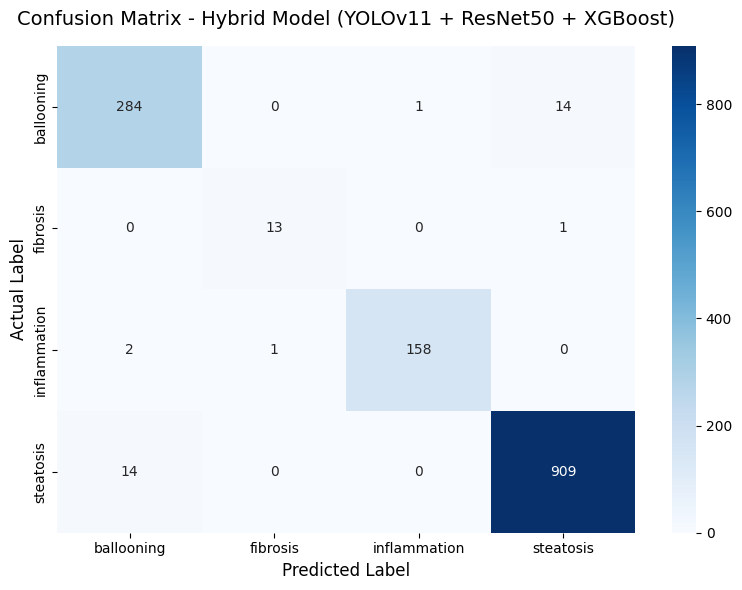

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Definisikan nama kelas penyakit liver kamu (sesuaikan urutan label 0, 1, 2, 3)
# Contoh: class_names = ['Normal', 'Fatty Liver', 'Cirrhosis', 'Hepatic Carcinoma']
class_names = ['ballooning', 'fibrosis', 'inflammation', 'steatosis']

# Hitung matriks
cm = confusion_matrix(y_test, y_pred)

# Plotting
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)

plt.title('Confusion Matrix - Hybrid Model (YOLOv11 + ResNet50 + XGBoost)', fontsize=14, pad=15)
plt.ylabel('Actual Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.tight_layout()

# Simpan otomatis ke Drive untuk ditaruh di Word skripsi
plt.savefig('/content/drive/MyDrive/hybrid_model_liver/confusion_matrix_final.png', dpi=300)
plt.show()

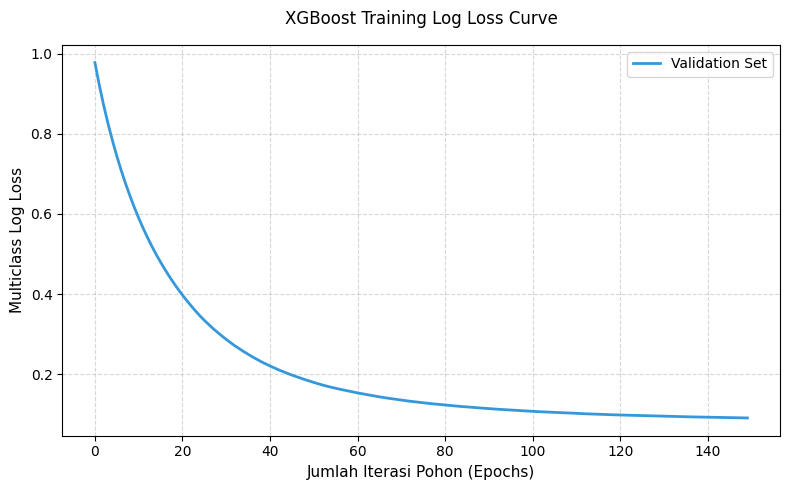

In [ ]:
import matplotlib.pyplot as plt

# Mengambil log evaluasi dari model XGBoost yang sudah dilatih
evals_result = xgb_model.evals_result()

# Mengambil nilai error/loss dari log (multi:softprob menggunakan mlogloss)
training_rounds = range(0, len(evals_result['validation_0']['mlogloss']))

plt.figure(figsize=(8, 5))
plt.plot(training_rounds, evals_result['validation_0']['mlogloss'], label='Validation Set', color='#3498db', linewidth=2)

plt.title('XGBoost Training Log Loss Curve', fontsize=12, pad=15)
plt.xlabel('Jumlah Iterasi Pohon (Epochs)', fontsize=11)
plt.ylabel('Multiclass Log Loss', fontsize=11)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

plt.savefig('/content/drive/MyDrive/hybrid_model_liver/xgboost_loss_curve.png', dpi=300)
plt.show()

⏳ Memuat semua model ke sistem...
✅ Semua model berhasil dimuat!

🔍 Step 1: YOLOv11 sedang mendeteksi organ liver...
🎯 YOLOv11 mendeteksi 3 objek liver.
🧬 Step 2: ResNet50 sedang mengekstrak fitur visual...
🧠 Step 3: XGBoost sedang menganalisis klasifikasi penyakit...

🎉 HASIL PREDIKSI AKHIR: ballooning
📈 Tingkat Keyakinan Model: 93.10%



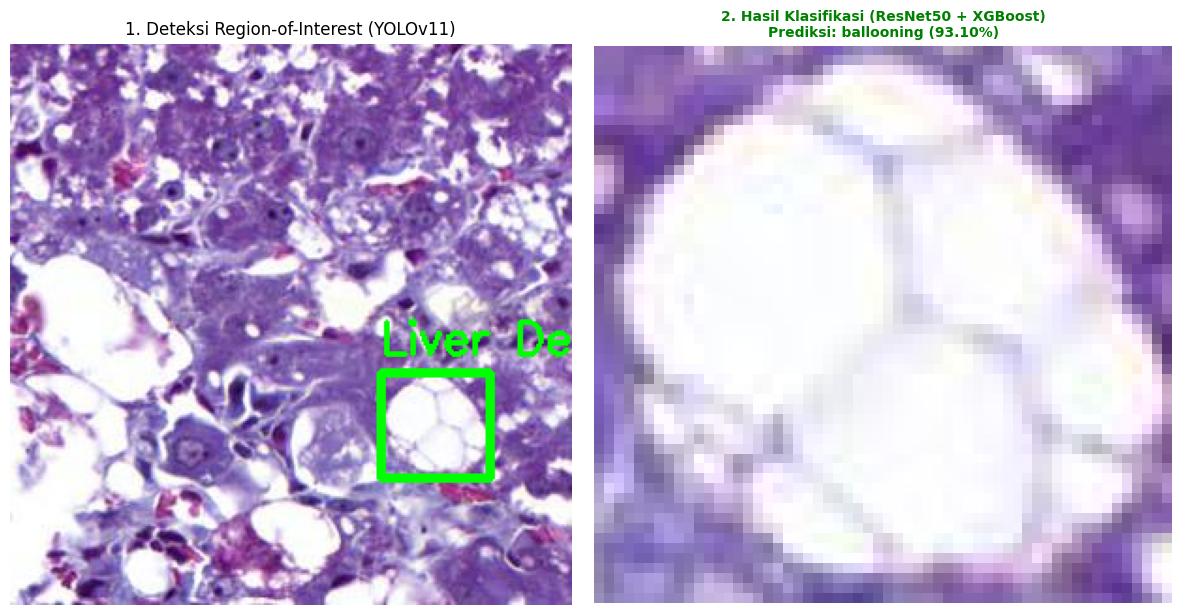

In [ ]:
import os
import cv2
import numpy as np
import torch
import pickle
from PIL import Image
import matplotlib.pyplot as plt
import torchvision.transforms as transforms
import torchvision.models as models
import torch.nn as nn
from ultralytics import YOLO

# ========================================================
# 1. SETUP PATH & ARTIFAK MODEL KEMENANGANMU
# ========================================================
# Path gambar baru yang mau kamu cek (Ganti dengan path gambar ujimu)
IMAGE_TEST_PATH = "/content/drive/MyDrive/DatasetAugmentedMergedLiver2/test/images/A_18_228_Masson_505_83_23_jpg.rf.bfbaccba01a7458679adb165d1f025dd.jpg"

YOLO_WEIGHTS = "/content/drive/MyDrive/yolo_results_Juni_2026/liver_yolo11_final_Juni_2026/weights/best.pt"
XGB_MODEL_PATH = "/content/drive/MyDrive/xgb_liver_model.pkl"

# Nama kelas asli skripsimu (sesuaikan urutannya)
class_names = ['ballooning', 'fibrosis', 'inflammation', 'steatosis']

device = "cuda" if torch.cuda.is_available() else "cpu"

# ========================================================
# 2. LOAD SEMUA MODEL (YOLO, RESNET, XGBOOST)
# ========================================================
print("⏳ Memuat semua model ke sistem...")
yolo_model = YOLO(YOLO_WEIGHTS)

resnet = models.resnet50(pretrained=True)
resnet = nn.Sequential(*list(resnet.children())[:-1])
resnet = resnet.to(device)
resnet.eval()
for param in resnet.parameters():
    param.requires_grad = False

with open(XGB_MODEL_PATH, "rb") as f:
    xgb_model = pickle.load(f)
print("✅ Semua model berhasil dimuat!\n")

# Transformasi gambar untuk standar input ResNet50
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

# ========================================================
# 3. EKSEKUSI INFERENCE PIPELINE HYBRID
# ========================================================
# Step A: Membaca Gambar Mentah Baru
img_bgr = cv2.imread(IMAGE_TEST_PATH)
if img_bgr is None:
    raise FileNotFoundError(f"Gambar tidak ditemukan di path: {IMAGE_TEST_PATH}")

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
h, w, _ = img_rgb.shape

# Step B: Deteksi Lokasi Organ Liver Menggunakan YOLOv11
print("🔍 Step 1: YOLOv11 sedang mendeteksi organ liver...")
yolo_results = yolo_model(img_rgb, conf=0.15, verbose=False)[0]

if len(yolo_results.boxes) == 0:
    print("❌ YOLOv11 tidak menemukan objek liver pada gambar tersebut. Proses dihentikan.")
else:
    print(f"🎯 YOLOv11 mendeteksi {len(yolo_results.boxes)} objek liver.")

    # Ambil bounding box pertama yang dideteksi oleh YOLO
    box = yolo_results.boxes[0]
    x1, y1, x2, y2 = map(int, box.xyxy[0])

    # Safe crop boundaries
    x1, y1 = max(0, x1), max(0, y1)
    x2, y2 = min(w, x2), min(h, y2)

    # Memotong (crop) gambar berdasarkan koordinat YOLO
    crop_img = img_rgb[y1:y2, x1:x2]

    if crop_img.size > 0 and crop_img.shape[0] >= 20 and crop_img.shape[1] >= 20:

        # Step C: Ekstraksi Fitur Menggunakan ResNet50
        print("🧬 Step 2: ResNet50 sedang mengekstrak fitur visual...")
        pil_crop = Image.fromarray(crop_img)
        tensor_img = transform(pil_crop).unsqueeze(0).to(device) # Tambahkan dimensi batch

        with torch.no_grad():
            resnet_features = resnet(tensor_img)

        # Reshape fitur angka menjadi format matriks 2D yang dipahami XGBoost
        features_flat = resnet_features.cpu().numpy().reshape(1, -1)

        # Step D: Klasifikasi Penyakit Menggunakan XGBoost (.pkl)
        print("🧠 Step 3: XGBoost sedang menganalisis klasifikasi penyakit...")
        pred_class_idx = xgb_model.predict(features_flat)[0]
        pred_proba = xgb_model.predict_proba(features_flat)[0]

        hasil_prediksi = class_names[pred_class_idx]
        persentase_keyakinan = pred_proba[pred_class_idx] * 100

        print("\n==========================================")
        print(f"🎉 HASIL PREDIKSI AKHIR: {hasil_prediksi}")
        print(f"📈 Tingkat Keyakinan Model: {persentase_keyakinan:.2f}%")
        print("==========================================\n")

        # ========================================================
        # 4. PLOTTING VISUALISASI HASIL NYATA UNTUK LAMPIRAN
        # ========================================================
        fig, axes = plt.subplots(1, 2, figsize=(12, 6))

        # Gambar Kiri: Gambar asli dengan bounding box dari YOLOv11
        img_with_box = img_rgb.copy()
        cv2.rectangle(img_with_box, (x1, y1), (x2, y2), (0, 255, 0), 3)
        cv2.putText(img_with_box, "Liver Detected", (x1, y1 - 10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
        axes[0].imshow(img_with_box)
        axes[0].set_title("1. Deteksi Region-of-Interest (YOLOv11)")
        axes[0].axis("off")

        # Gambar Kanan: Hasil potongan (crop) liver yang dianalisis
        axes[1].imshow(crop_img)
        axes[1].set_title(f"2. Hasil Klasifikasi (ResNet50 + XGBoost)\nPrediksi: {hasil_prediksi} ({persentase_keyakinan:.2f}%)",
                          fontsize=10, color="green", fontweight="bold")
        axes[1].axis("off")

        plt.tight_layout()
        plt.show()

Training tanpa ResNet

In [ ]:
import os
import cv2
import numpy as np
from ultralytics import YOLO
from tqdm import tqdm

# ======================
# LOAD MODEL YOLO
# ======================
model = YOLO("/content/drive/MyDrive/yolo_results_Juni_2026/liver_yolo11_final_Juni_2026/weights/best.pt")

# ======================
# PATH DATA
# ======================
image_folder = "/content/drive/MyDrive/DatasetAugmentedMergedLiver2/train/images"

X = []
y = []

# ======================
# LOOP DATA
# ======================
for img_name in tqdm(os.listdir(image_folder)):
    img_path = os.path.join(image_folder, img_name)
    image = cv2.imread(img_path)

    if image is None:
        continue

    results = model(image)[0]

    for box in results.boxes:
        cls = int(box.cls[0])
        conf = float(box.conf[0])
        x1, y1, x2, y2 = map(float, box.xyxy[0])

        # 🔥 FEATURE DARI YOLO
        feature = [x1, y1, x2, y2, conf]

        X.append(feature)
        y.append(cls)

X = np.array(X)
y = np.array(y)

print("Shape X:", X.shape)
print("Shape y:", y.shape)

np.save("/content/X_yolo_only.npy", X)
np.save("/content/y_yolo_only.npy", y)

  0%|          | 0/21658 [00:00<?, ?it/s]


0: 640x640 (no detections), 14.6ms
Speed: 13.8ms preprocess, 14.6ms inference, 2.8ms postprocess per image at shape (1, 3, 640, 640)


  0%|          | 1/21658 [00:03<20:18:04,  3.37s/it]


0: 640x640 (no detections), 12.3ms
Speed: 2.7ms preprocess, 12.3ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)


  0%|          | 2/21658 [00:04<11:59:57,  1.99s/it]


0: 640x640 (no detections), 12.6ms
Speed: 2.6ms preprocess, 12.6ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)


... (4,816 outputs left out)

 11%|█         | 2411/21658 [30:26<3:45:31,  1.42it/s]


0: 640x640 (no detections), 14.5ms
Speed: 2.5ms preprocess, 14.5ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)


 11%|█         | 2412/21658 [30:27<4:03:05,  1.32it/s]


KeyboardInterrupt: 

In [ ]:
# ======================
# 1. IMPORT LIBRARY
# ======================
import os
import random
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# ======================
# 2. PATH DATASET
# ======================
# Ganti sesuai lokasi dataset kamu
dataset_path = "/content/drive/MyDrive/DatasetAugmentedMergedLiver2/train/images"

# Nama kelas (urutannya sesuai label kamu)
class_names = ["ballooning", "fibrosis", "inflammation", "steatosis"]

# ======================
# 3. AMBIL 1 GAMBAR ACAK PER KELAS
# ======================
images = []
labels = []

for class_id, class_name in enumerate(class_names):
    class_images = []

    # cari semua file gambar yang punya label class ini
    for file in os.listdir(dataset_path):
        if file.endswith((".jpg", ".png", ".jpeg")):
            label_path = file.replace(".jpg", ".txt").replace(".png", ".txt").replace(".jpeg", ".txt")
            label_path = os.path.join(dataset_path.replace("images", "labels"), label_path)

            if os.path.exists(label_path):
                with open(label_path, "r") as f:
                    lines = f.readlines()
                    for line in lines:
                        cls = int(line.split()[0])
                        if cls == class_id:
                            class_images.append(file)
                            break

    if len(class_images) == 0:
        raise ValueError(f"Tidak ada gambar untuk class {class_name}")

    selected = random.choice(class_images)
    img_path = os.path.join(dataset_path, selected)

    images.append(mpimg.imread(img_path))
    labels.append(class_name)

# ======================
# 4. TAMPILKAN HORIZONTAL
# ======================
plt.figure(figsize=(16, 4))

for i in range(4):
    plt.subplot(1, 4, i+1)
    plt.imshow(images[i])
    plt.title(labels[i], fontsize=12, fontweight='bold')
    plt.axis("off")

plt.tight_layout()
plt.show()

# ======================
# 5. SIMPAN GAMBAR
# ======================
output_path = "/content/drive/MyDrive/visualisasi_4_kelas_liver.png"
plt.savefig(output_path, dpi=300, bbox_inches='tight')

print("Gambar berhasil disimpan di:", output_path)

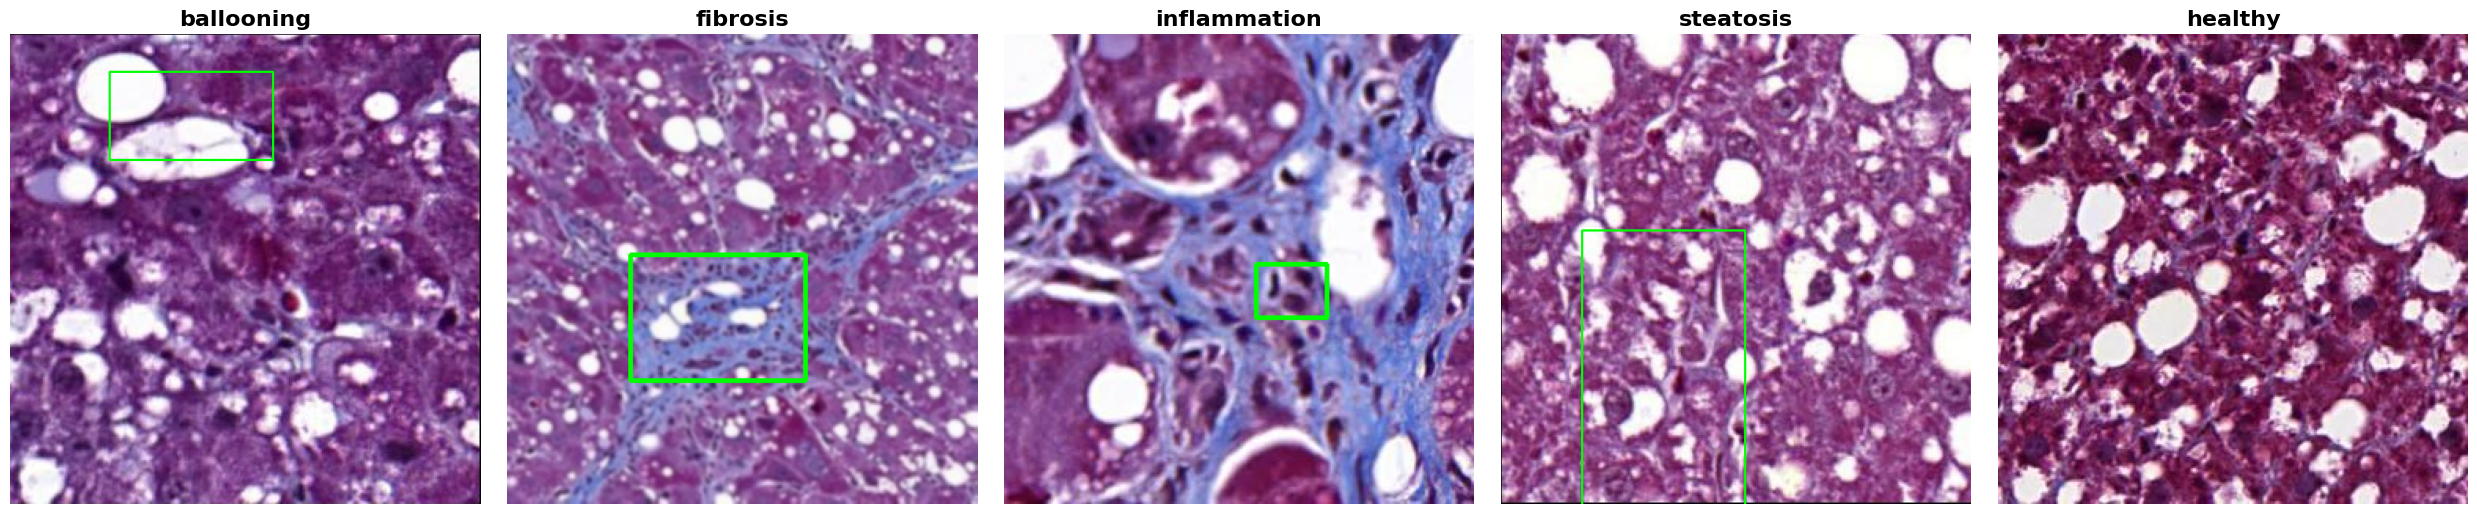

✅ Visualisasi dengan satu bounding box per class berhasil disimpan.


In [ ]:
import os
import cv2
import random
import matplotlib.pyplot as plt

# Configuration
IMAGE_DIR = "/content/drive/MyDrive/DatasetAugmentedMergedLiver2/train/images"
LABEL_DIR = "/content/drive/MyDrive/DatasetAugmentedMergedLiver2/train/labels"
class_names = ['ballooning', 'fibrosis', 'inflammation', 'steatosis', 'healthy']

def get_random_sample(target_cls):
    all_images = [f for f in os.listdir(IMAGE_DIR) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    random.shuffle(all_images)

    for img_file in all_images:
        base_name = os.path.splitext(img_file)[0]
        lbl_path = os.path.join(LABEL_DIR, base_name + ".txt")

        # Logic for 'healthy' class: no label file exists or label file is empty
        if target_cls == 4:
            if not os.path.exists(lbl_path) or os.stat(lbl_path).st_size == 0:
                return os.path.join(IMAGE_DIR, img_file), None

        # Logic for specific disease classes
        elif os.path.exists(lbl_path):
            with open(lbl_path, 'r') as f:
                lines = f.readlines()
                for line in lines:
                    parts = line.split()
                    if parts and int(parts[0]) == target_cls:
                        return os.path.join(IMAGE_DIR, img_file), lbl_path
    return None, None

# Visualization with Bounding Boxes (Only ONE box per image)
fig, axes = plt.subplots(1, 5, figsize=(25, 5))

for i in range(5):
    img_path, lbl_path = get_random_sample(i)

    if img_path:
        img = cv2.imread(img_path)
        h, w, _ = img.shape
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Draw bounding boxes if label exists
        if lbl_path:
            with open(lbl_path, 'r') as f:
                for line in f.readlines():
                    parts = line.split()
                    if parts and int(parts[0]) == i:
                        # Draw only the first box found for this class
                        xc, yc, nw, nh = map(float, parts[1:5])
                        x1 = int((xc - nw/2) * w)
                        y1 = int((yc - nh/2) * h)
                        x2 = int((xc + nw/2) * w)
                        y2 = int((yc + nh/2) * h)
                        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
                        break # <--- KEY CHANGE: stop after drawing one box

        axes[i].imshow(img)
        axes[i].set_title(class_names[i], fontsize=16, fontweight='bold')
        axes[i].axis('off')
    else:
        axes[i].text(0.5, 0.5, f"No Image for\n{class_names[i]}", ha='center')
        axes[i].axis('off')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/liver_data_viz_single_box.png', dpi=300)
plt.show()

print("✅ Visualisasi dengan satu bounding box per class berhasil disimpan.")

In [ ]:
from ultralytics import YOLO

model = YOLO("/content/drive/MyDrive/yolo_results_Juni_2026/liver_yolo11_final_Juni_2026/weights/best.pt")

In [ ]:
metrics = model.val(
    data="/content/drive/MyDrive/DatasetAugmentedMergedLiver2/data.yaml",
    split="test"
)

Ultralytics 8.4.83 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
val: Fast image access ✅ (ping: 0.5±0.2 ms, read: 0.0±0.0 MB/s, size: 37.4 KB)
val: Scanning /content/drive/MyDrive/DatasetAugmentedMergedLiver2/test/labels... 459 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 459/459 9.2it/s 50.2s
val: /content/drive/MyDrive/DatasetAugmentedMergedLiver2/test/images/B_18_228_Masson_505_91_30_jpg.rf.6514691a5acf7ab6a0dd4ecc632678f0.jpg: 1 duplicate labels removed
val: New cache created: /content/drive/MyDrive/DatasetAugmentedMergedLiver2/test/labels.cache
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 422, len(boxes) = 1412. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 29/29 5.3it/s 5.4s
     

In [ ]:
# Menggunakan atribut yang benar sesuai dengan dokumentasi Ultralytics
precision = metrics.box.mp      # Mean Precision
recall = metrics.box.mr         # Mean Recall
map50 = metrics.box.map50       # mAP@50
map5095 = metrics.box.map       # mAP@50-95

print(f"Mean Precision: {precision:.4f}")
print(f"Mean Recall: {recall:.4f}")
print(f"mAP@50: {map50:.4f}")
print(f"mAP@50-95: {map5095:.4f}")

Mean Precision: 0.5895
Mean Recall: 0.6076
mAP@50: 0.6135
mAP@50-95: 0.4307


In [ ]:
f1 = 2 * (precision * recall) / (precision + recall)
print("F1-score:", f1)

F1-score: 0.5984319404756678


In [ ]:
from sklearn.metrics import classification_report
import os

image_dir = "/content/drive/MyDrive/DatasetAugmentedMergedLiver2/test/images"
label_dir = "/content/drive/MyDrive/DatasetAugmentedMergedLiver2/test/labels"

y_true = []
y_pred = []

for img_name in os.listdir(image_dir):
    img_path = os.path.join(image_dir, img_name)
    label_path = os.path.join(label_dir, img_name.replace(".jpg", ".txt"))

    # Ground truth
    with open(label_path, "r") as f:
        gt = [int(line.split()[0]) for line in f.readlines()]

    # Prediksi YOLO
    results = model(img_path)
    preds = [int(box.cls[0]) for box in results[0].boxes]

    # Samakan jumlah (simple matching)
    min_len = min(len(gt), len(preds))
    y_true.extend(gt[:min_len])
    y_pred.extend(preds[:min_len])

# Evaluasi
print(classification_report(y_true, y_pred))


image 1/1 /content/drive/MyDrive/DatasetAugmentedMergedLiver2/test/images/A_18_217_212_56_22_jpg.rf.261af1b4d1fe5a273589a4f4f8cb276e.jpg: 640x640 1 inflammation, 11.8ms
Speed: 3.6ms preprocess, 11.8ms inference, 3.1ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/drive/MyDrive/DatasetAugmentedMergedLiver2/test/images/A_18_228_Masson_207_34_34_jpg.rf.0471cf32e06ba7259c9e3a6d3fcad847.jpg: 640x640 (no detections), 12.2ms
Speed: 3.1ms preprocess, 12.2ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/drive/MyDrive/DatasetAugmentedMergedLiver2/test/images/A_18_229_Masson_201_36_15_jpg.rf.1911b3cf7f72c41a990f2d2cbdfb9baa.jpg: 640x640 3 balloonings, 11.5ms
Speed: 2.1ms preprocess, 11.5ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/drive/MyDrive/DatasetAugmentedMergedLiver2/test/images/A_15_242_212_22_18_jpg.rf.2507ed18caf750785ad603530130319e.jpg: 640x640 (no detections), 11.1ms
Speed: 2.1ms p

YOLO + XGB

In [ ]:
from ultralytics import YOLO

model = YOLO("/content/drive/MyDrive/yolo_results_Juni_2026/liver_yolo11_final_Juni_2026/weights/best.pt")

In [ ]:
import os
import numpy as np

image_dir = "/content/drive/MyDrive/DatasetAugmentedMergedLiver2/train/images"
label_dir = "/content/drive/MyDrive/DatasetAugmentedMergedLiver2/train/labels"

X = []
y = []

for img_name in os.listdir(image_dir):
    img_path = os.path.join(image_dir, img_name)
    label_path = os.path.join(label_dir, img_name.replace(".jpg", ".txt"))

    # ground truth
    if not os.path.exists(label_path):
        continue

    with open(label_path, "r") as f:
        gt_lines = f.readlines()

    results = model(img_path)
    boxes = results[0].boxes

    for i, box in enumerate(boxes):
        if i >= len(gt_lines):
            break

        cls_gt = int(gt_lines[i].split()[0])

        x, y_center, w, h = box.xywh[0].cpu().numpy()
        conf = box.conf[0].cpu().numpy()

        feature = [x, y_center, w, h, conf]

        X.append(feature)
        y.append(cls_gt)


image 1/1 /content/drive/MyDrive/DatasetAugmentedMergedLiver2/train/images/fib_aug_1570_0.jpg: 640x640 (no detections), 12.4ms
Speed: 2.6ms preprocess, 12.4ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/drive/MyDrive/DatasetAugmentedMergedLiver2/train/images/fib_aug_1570_1.jpg: 640x640 (no detections), 12.5ms
Speed: 2.4ms preprocess, 12.5ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/drive/MyDrive/DatasetAugmentedMergedLiver2/train/images/fib_aug_1570_2.jpg: 640x640 (no detections), 12.4ms
Speed: 2.4ms preprocess, 12.4ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/drive/MyDrive/DatasetAugmentedMergedLiver2/train/images/fib_aug_1570_3.jpg: 640x640 (no detections), 12.2ms
Speed: 2.4ms preprocess, 12.2ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/drive/MyDrive/DatasetAugmentedMergedLiver2/train/images/fib_aug_1571_0.jpg: 640x

KeyboardInterrupt: 

In [ ]:
from ultralytics import YOLO

model = YOLO("/content/drive/MyDrive/YOLOv11_training_liver/liver_disease_detection/weights/best.pt")

model.info()

YOLO11n summary: 182 layers, 2,590,620 parameters, 0 gradients, 6.4 GFLOPs


(182, 2590620, 0, 6.443827200000001)